# Short-form vs long-form decoding: justifying long-form transcription

Whisper processes audio in 30-second windows. **Short-form** decoding transcribes a single window, so it cannot be
used on recordings longer than 30 s without cutting them off. **Sequential long-form** decoding slides the window
along the recording and can transcribe any length.

Some recordings in the study are longer than 30 s, so using short-form would mean either cutting those recordings,
dropping them, or decoding them differently from the rest. This notebook shows that long-form can be used for
**every** recording instead:

1. On recordings short enough for **both** modes (SAA, under 30 s), long-form gives essentially the same WER.
2. The small changes it makes are not directional, are mostly a single word, and do not fall on particular accents.
3. Recordings over 30 s are much more common for non-native speakers, so mixing decode modes would mix the decode
   mode up with accent.
4. Long-form repetition (hallucination loops) is checked for in both modes.

The comparison uses SAA because that is where the > 30 s recordings are: every speaker reads the same paragraph, and
non-native speakers often take longer than 30 s to read it. AfriSpeech clips are all well under 30 s.

## 0. Configuration

In [1]:
from pathlib import Path

RESULTS_ROOT = Path("../results/asr/")

# Decode-mode runs on the under-30 s subset with one entry per model, each with a short-form and a long-form folder.
# Base is the model used in the study; add "small" (or another model) only as an optional robustness check.
DECODE_RUNS = {
    "base": {
        "short": RESULTS_ROOT / "runs/decode_base_short",
        "long":  RESULTS_ROOT / "runs/decode_base_long",
    },
    # "small": {
    #     "short": RESULTS_ROOT / "runs/decode_small_short",
    #     "long":  RESULTS_ROOT / "runs/decode_small_long",
    # },
}
PRIMARY_MODEL = "base"

SCORED_PATTERN = "scored.csv"
TRANSCRIPTIONS_PATTERN = "transcriptions.csv"

# Manifest of the under-30 s subset used for this comparison (accent labels + durations)
SUBSET_MANIFEST_PATH = RESULTS_ROOT / "runs/decode_base_long/manifest_snapshot.csv"

# Manifest of the FULL study set (all durations), used in section 7
FULL_MANIFEST_PATH = RESULTS_ROOT / "runs/analysis_base_long/manifest_snapshot.csv"

# Optional: the full-study long-form run, used to check for repetition on recordings over 30 s (section 8)
FULL_LONG_RUN_DIR = RESULTS_ROOT / "runs/analysis_base_long"     # set to None to skip

ACCENT_COL = "accent_group"
DURATION_COL = "duration_s"
REFERENCE_ACCENT = "american_english"
SHORT_FORM_LIMIT_S = 30.0

REPEAT_NGRAM = 3          # a hypothesis is flagged as repeating if some 3-word phrase appears
REPEAT_MIN_COUNT = 3      # at least this many times, and more often than in the reference

FIG_DIR = Path("figures")

In [2]:
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
FIG_DIR.mkdir(parents=True, exist_ok=True)

INK, GREY = "#33322e", "#b5b4ad"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e2dc", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8980", "axes.labelcolor": INK, "xtick.color": "#5c5b55",
    "ytick.color": "#5c5b55", "font.size": 10, "legend.frameon": False,
})
REPORT_STYLE = {"font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
                "legend.fontsize": 7.5}

def save_report_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    print(f"Saved {FIG_DIR / name}.pdf / .png")

## 1. Load and pair the two runs

In [3]:
def find_one(folder, pattern):
    folder = Path(folder)
    if not folder.is_dir():
        parent = folder.parent
        siblings = sorted(p.name for p in parent.iterdir() if p.is_dir()) if parent.is_dir() else []
        raise FileNotFoundError(f"Folder not found: {folder.resolve()} (running from {Path.cwd()})\n"
                                + ("Folders that exist there:\n  " + "\n  ".join(siblings) if siblings else ""))
    matches = sorted(folder.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one file matching '{pattern}' in {folder.resolve()}, "
                                f"found {[p.name for p in matches]}")
    return matches[0]

def load_run(folder):
    scored = pd.read_csv(find_one(folder, SCORED_PATTERN))
    trans = pd.read_csv(find_one(folder, TRANSCRIPTIONS_PATTERN))
    scored = scored[(scored["transcription_status"] == "ok") & (scored["scoring_status"] == "ok")]
    df = scored.merge(trans[["sample_id", "transcription_raw", "real_time_factor"]], on="sample_id", how="left")
    df["errors"] = df["substitutions"] + df["deletions"] + df["insertions"]
    df["hypothesis_norm"] = df["hypothesis_norm"].fillna("").astype(str).str.split().str.join(" ")
    df["reference_norm"] = df["reference_norm"].fillna("").astype(str).str.split().str.join(" ")
    return df

subset_manifest = pd.read_csv(SUBSET_MANIFEST_PATH)[["sample_id", ACCENT_COL, DURATION_COL]]
subset_manifest = subset_manifest.rename(columns={ACCENT_COL: "accent", DURATION_COL: "duration_s"})

paired = {}
for model, folders in DECODE_RUNS.items():
    short, long = load_run(folders["short"]), load_run(folders["long"])
    print(f"{model}: short-form = {short['model_name'].iloc[0]} / {short['decode_mode'].iloc[0]}, "
          f"long-form = {long['model_name'].iloc[0]} / {long['decode_mode'].iloc[0]}")
    if short["decode_mode"].iloc[0] == long["decode_mode"].iloc[0]:
        raise ValueError(f"{model}: both folders contain the same decode mode - check DECODE_RUNS")
    keep = ["sample_id", "dataset", "reference_norm", "hypothesis_norm", "transcription_raw", "wer", "errors",
            "substitutions", "deletions", "insertions", "n_reference_words", "real_time_factor"]
    p = short[keep].merge(long[keep].drop(columns="dataset"), on="sample_id", suffixes=("_short", "_long"))
    p = p.merge(subset_manifest, on="sample_id", how="left")
    print(f"  {len(p)} recordings in both runs "
          f"({len(short) - len(p)} only in short-form, {len(long) - len(p)} only in long-form)")
    if (p["reference_norm_short"] != p["reference_norm_long"]).any():
        print("  WARNING: some normalised references differ between the two runs")
    if p["accent"].isna().any():
        print(f"  WARNING: {p['accent'].isna().sum()} recordings have no accent label in the subset manifest")
    print(f"  Duration range: {p['duration_s'].min():.1f}-{p['duration_s'].max():.1f} s "
          f"(all under {SHORT_FORM_LIMIT_S:.0f} s: {(p['duration_s'] < SHORT_FORM_LIMIT_S).all()})")
    paired[model] = p

d = paired[PRIMARY_MODEL].copy()
d["native"] = np.where(d["accent"] == REFERENCE_ACCENT, REFERENCE_ACCENT, "non-" + REFERENCE_ACCENT)
print(f"\nPrimary model: {PRIMARY_MODEL}")
display(d["accent"].value_counts().rename("recordings").to_frame().T)

base: short-form = openai/whisper-base / short_form, long-form = openai/whisper-base / sequential_long_form
  370 recordings in both runs (0 only in short-form, 0 only in long-form)
  Duration range: 16.5-30.0 s (all under 30 s: True)

Primary model: base


accent,american_english,hindi,amharic,kiswahili,hausa,tigrigna,yoruba
recordings,331,15,9,6,5,3,1


In [4]:
def pooled_wer(errors, n_words):
    return errors.sum() / n_words.sum()

def word_edit_distance(a, b):
    """Number of word insertions, deletions and substitutions needed to turn sentence a into sentence b."""
    a, b = a.split(), b.split()
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        for j, wb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (wa != wb))
        prev = cur
    return prev[-1]

def add_comparison_columns(p):
    p = p.copy()
    p["transcript_changed"] = p["hypothesis_norm_short"] != p["hypothesis_norm_long"]
    p["wer_changed"] = ~np.isclose(p["wer_short"], p["wer_long"])
    p["error_change"] = p["errors_long"] - p["errors_short"]     # + = long-form made more errors
    p["outcome"] = np.select([p["error_change"] < 0, p["error_change"] > 0], ["long better", "long worse"], "same")
    p["words_differing"] = [word_edit_distance(s, l) for s, l in zip(p["hypothesis_norm_short"], p["hypothesis_norm_long"])]
    return p

d = add_comparison_columns(d)
paired = {m: add_comparison_columns(p) for m, p in paired.items()}

**Analysis on data used:** 

The comparison uses the 370 SAA recordings that are under 30 s, so both decode modes can transcribe the whole recording (durations 16.5–30.0 s). Every recording was transcribed in both modes with Whisper-base, and the normalised references are identical, so any difference comes only from the decoding. The subset is dominated by American English (331 recordings); the other 39 are Hindi (15), Amharic (9), Kiswahili (6), Hausa (5), Tigrigna (3) and Yoruba (1). Non-American speakers are under-represented here because many of them take longer than 30 s to read the passage (section 7).

## 2. Overall WER

* **Mean WER** = average of the per-recording WERs. 
* **Pooled WER** = total errors / total reference words. In SAA every
speaker reads the same 69-word passage, so the two are identical here.

In [5]:
def overall_row(p, label):
    return {
        "model": label,
        "recordings": len(p),
        "mean WER short %": p["wer_short"].mean() * 100,
        "mean WER long %": p["wer_long"].mean() * 100,
        "difference (pp, long - short)": (p["wer_long"].mean() - p["wer_short"].mean()) * 100,
        "pooled WER short %": pooled_wer(p["errors_short"], p["n_reference_words_short"]) * 100,
        "pooled WER long %": pooled_wer(p["errors_long"], p["n_reference_words_long"]) * 100,
        "median WER short %": p["wer_short"].median() * 100,
        "median WER long %": p["wer_long"].median() * 100,
        "total errors short": int(p["errors_short"].sum()),
        "total errors long": int(p["errors_long"].sum()),
    }
overall = pd.DataFrame([overall_row(d, PRIMARY_MODEL)]).set_index("model")
display(overall.T.round(3))

model,base
recordings,370.000
mean WER short %,2.158
mean WER long %,2.244
"difference (pp, long - short)",0.086
pooled WER short %,2.158
pooled WER long %,2.244
median WER short %,1.449
median WER long %,1.449
total errors short,551.000
total errors long,573.000


**Analysis of overall WER:** 

Long-form gives a mean WER of 2.24% against 2.16% for short-form, a difference of **+0.09 percentage points**. Across all 370 recordings, long-form made 573 errors and short-form 551: 22 extra errors out of 25,530 reference words. The median WER is the same in both modes (1.45%, i.e. one error in the 69-word passage). In practical terms the two modes give the same WER.

## 3. How many recordings changed?

* **Transcript changed:** the normalised hypothesis text is different in any way.
* **WER changed:** the change actually affected the score (a transcript can change without changing the WER, e.g.
  one wrong word replaced by a different wrong word).
* **Long better / worse / same:**  based on the number of errors.

In [6]:
def counts_table(p):
    n = len(p)
    rows = {
        "transcript identical": (~p["transcript_changed"]).sum(),
        "transcript changed": p["transcript_changed"].sum(),
        "WER identical": (~p["wer_changed"]).sum(),
        "WER changed": p["wer_changed"].sum(),
        "long-form better (fewer errors)": (p["outcome"] == "long better").sum(),
        "long-form worse (more errors)": (p["outcome"] == "long worse").sum(),
        "same number of errors": (p["outcome"] == "same").sum(),
    }
    t = pd.DataFrame({"recordings": rows})
    t["%"] = t["recordings"] / n * 100
    return t

change_counts = counts_table(d)
display(change_counts.round(1))

,recordings,%
transcript identical,307,83.0
transcript changed,63,17.0
WER identical,318,85.9
WER changed,52,14.1
long-form better (fewer errors),20,5.4
long-form worse (more errors),32,8.6
same number of errors,318,85.9


In [21]:
cols = ["substitutions", "deletions", "insertions", "errors"]

totals = pd.DataFrame({
    "short-form": [int(d[f"{c}_short"].sum()) for c in cols],
    "long-form":  [int(d[f"{c}_long"].sum()) for c in cols],
}, index=cols)
totals["change"] = totals["long-form"] - totals["short-form"]
totals["% change"] = totals["change"] / totals["short-form"] * 100
display(totals.round(1))

per_recording = pd.DataFrame({
    "recordings differing": [int((d[f"{c}_short"] != d[f"{c}_long"]).sum()) for c in cols],
}, index=cols)
per_recording["% of recordings"] = per_recording["recordings differing"] / len(d) * 100
display(per_recording.round(1))

,short-form,long-form,change,% change
substitutions,375,392,17,4.5
deletions,73,73,0,0.0
insertions,103,108,5,4.9
errors,551,573,22,4.0


,recordings differing,% of recordings
substitutions,39,10.5
deletions,16,4.3
insertions,16,4.3
errors,52,14.1


## 4. Is the change directional?

If long-form were systematically worse (or better), most of the changed recordings would move the same way.

* **Sign test:**  among recordings whose error count changed, is "long worse" more common than "long better" than
  a 50/50 split would predict?

In [7]:
better = int((d["outcome"] == "long better").sum())
worse = int((d["outcome"] == "long worse").sum())
sign = stats.binomtest(worse, better + worse, 0.5)
print(f"Of the {better + worse} recordings whose error count changed: "
      f"{worse} worse with long-form ({worse / (better + worse):.0%}), {better} better ({better / (better + worse):.0%})")
print(f"Sign test: p = {sign.pvalue:.3f}")

changed = d[d["wer_changed"]]
w = stats.wilcoxon(changed["wer_long"], changed["wer_short"])
print(f"Net effect: {int(d['errors_long'].sum() - d['errors_short'].sum()):+d} errors over "
      f"{int(d['n_reference_words_short'].sum())} reference words")

Of the 52 recordings whose error count changed: 32 worse with long-form (62%), 20 better (38%)
Sign test: p = 0.126
Net effect: +22 errors over 25530 reference words


**Analysis of direction:** 

Among the 52 recordings whose WER changed, long-form was worse in 32 and better in 20. That is a slight lean towards long-form being worse, but it is not statistically significant (sign test p = 0.13), and its size is negligible with only 22 extra errors in 25,530 words. Most of the extra errors are substitutions (+17), with a few insertions (+5) and no extra deletions; therefore, long-form does not drop more words overall. The changes behave like small random differences rather than a systematic bias.

## 5. How big are the changes?

Two ways of measuring the size of a change, for every recording:

* **Change in error count** (long − short): how many more (+) or fewer (−) errors long-form made. This method considers errors against the reference.
* **Words differing between the two transcripts**: the word-level edit distance between the short-form and long-form
  hypotheses, regardless of whether either is correct. This method compares the two transcripts with each other only.

In [8]:
def bucket(v, cap=3):
    v = int(v)
    if v >= cap:
        return f"+{cap} or more"
    if v <= -cap:
        return f"-{cap} or fewer"
    return f"{v:+d}" if v else "0"

order_err = ["-3 or fewer", "-2", "-1", "0", "+1", "+2", "+3 or more"]
err_dist = d["error_change"].map(bucket).value_counts().reindex(order_err, fill_value=0).rename("recordings").to_frame()
err_dist["%"] = err_dist["recordings"] / len(d) * 100
print("Change in number of errors (long-form minus short-form):")
display(err_dist.round(1))

words = d["words_differing"].clip(upper=4).map(lambda v: "4 or more" if v >= 4 else str(v))
word_dist = words.value_counts().reindex(["0", "1", "2", "3", "4 or more"], fill_value=0).rename("recordings").to_frame()
word_dist["% of all"] = word_dist["recordings"] / len(d) * 100
word_dist["% of changed transcripts"] = word_dist["recordings"] / d["transcript_changed"].sum() * 100
word_dist.loc["0", "% of changed transcripts"] = np.nan
print("Number of words that differ between the short-form and long-form transcripts:")
display(word_dist.round(1))

Change in number of errors (long-form minus short-form):


,recordings,%
error_change,,
-3 or fewer,1,0.3
-2,6,1.6
-1,13,3.5
0,318,85.9
+1,21,5.7
+2,6,1.6
+3 or more,5,1.4


Number of words that differ between the short-form and long-form transcripts:


,recordings,% of all,% of changed transcripts
words_differing,,,
0,307,83.0,NaN
1,34,9.2,54.0
2,16,4.3,25.4
3,6,1.6,9.5
4 or more,7,1.9,11.1


Saved figures\decode_mode_error_change.pdf / .png


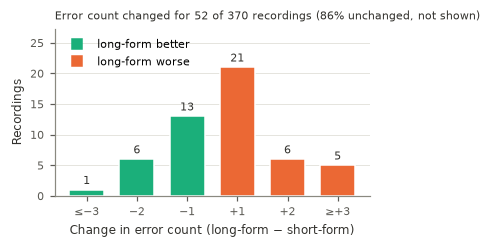

In [9]:
changed_buckets = [b for b in order_err if b != "0"]
n_changed = int((d["error_change"] != 0).sum())
counts = err_dist.loc[changed_buckets, "recordings"]
with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 2.3))
    x = np.arange(len(changed_buckets))
    colors = [AQUA if b.startswith("-") else ORANGE for b in changed_buckets]
    ax.bar(x, counts, color=colors, width=0.7, edgecolor="white", linewidth=1)
    for xi, n in zip(x, counts):
        ax.annotate(f"{n}", (xi, n), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom",
                    fontsize=7, color=INK)
    ax.set_xticks(x, ["≤−3", "−2", "−1", "+1", "+2", "≥+3"])
    ax.set_xlabel("Change in error count (long-form − short-form)")
    ax.set_ylabel("Recordings")
    ax.set_ylim(0, counts.max() * 1.3)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"Error count changed for {n_changed} of {len(d)} recordings "
                 f"({(len(d) - n_changed) / len(d):.0%} unchanged, not shown)", loc="left", fontsize=7.5, color=INK)
    ax.plot([], [], "s", color=AQUA, label="long-form better")
    ax.plot([], [], "s", color=ORANGE, label="long-form worse")
    ax.legend(loc="upper left")
    plt.tight_layout()
    save_report_figure(fig, "decode_mode_error_change")
    plt.show()

**Analysis of size of the changes:** 

The changes are small:
* Of the 52 recordings whose error count changed, **65% changed by a single error** (13 better, 21 worse), 23% by two errors and 12% by three or more.
* Of the 63 transcripts that changed at all, **54% differ by one word** and 79% by at most two words.

The typical change is a near-homophone at a single position, for example *bob → bop*, *snow peas → snowpeed* or *wednesday → once day*. The few larger changes are rewordings of the last few words of the passage (e.g. *wednesday at the train station → when she has a train station*).

## 6. Does the decode mode affect some accents more than others?

If long-form changed the WER mainly for one accent, it could bias the accent comparison even though the overall
change is small.

In [10]:
def by_group(p, col):
    rows = []
    for g, x in p.groupby(col):
        rows.append({
            col: g, "recordings": len(x),
            "mean WER short %": x["wer_short"].mean() * 100,
            "mean WER long %": x["wer_long"].mean() * 100,
            "difference (pp)": (x["wer_long"].mean() - x["wer_short"].mean()) * 100,
            "WER changed": int(x["wer_changed"].sum()),
            "% WER changed": x["wer_changed"].mean() * 100,
            "long better": int((x["outcome"] == "long better").sum()),
            "long worse": int((x["outcome"] == "long worse").sum()),
        })
    return pd.DataFrame(rows).set_index(col).sort_values("recordings", ascending=False)

print("Per accent group:")
display(by_group(d, "accent").round(2))
print("Reference vs everyone else:")
native_table = by_group(d, "native")
display(native_table.round(2))

Per accent group:


,recordings,mean WER short %,mean WER long %,difference (pp),WER changed,% WER changed,long better,long worse
accent,,,,,,,,
american_english,331,1.76,1.83,0.08,43,12.99,16,27
hindi,15,2.71,2.51,-0.19,2,13.33,2,0
amharic,9,9.50,9.34,-0.16,3,33.33,2,1
kiswahili,6,6.04,6.28,0.24,1,16.67,0,1
hausa,5,6.09,6.96,0.87,2,40.00,0,2
tigrigna,3,8.21,8.21,0.00,0,0.00,0,0
yoruba,1,0.00,4.35,4.35,1,100.00,0,1


Reference vs everyone else:


,recordings,mean WER short %,mean WER long %,difference (pp),WER changed,% WER changed,long better,long worse
native,,,,,,,,
american_english,331,1.76,1.83,0.08,43,12.99,16,27
non-american_english,39,5.57,5.72,0.15,9,23.08,4,5


In [11]:
ref = d[d["native"] == REFERENCE_ACCENT]
non = d[d["native"] != REFERENCE_ACCENT]

# Is a WER change more likely for non-reference speakers?
table = [[int(non["wer_changed"].sum()), int((~non["wer_changed"]).sum())],
         [int(ref["wer_changed"].sum()), int((~ref["wer_changed"]).sum())]]
print(f"Share of recordings whose WER changed: non-reference {non['wer_changed'].mean():.1%} "
      f"vs reference {ref['wer_changed'].mean():.1%}  ")

# Is the size/direction of the change different?
print(f"Mean WER change (long - short): non-reference {(non['wer_long'] - non['wer_short']).mean()*100:+.2f} pp "
      f"vs reference {(ref['wer_long'] - ref['wer_short']).mean()*100:+.2f} pp")
print(f"\nNote: only {len(non)} non-reference recordings are under {SHORT_FORM_LIMIT_S:.0f} s, so this test has limited power.")

Share of recordings whose WER changed: non-reference 23.1% vs reference 13.0%  
Mean WER change (long - short): non-reference +0.15 pp vs reference +0.08 pp

Note: only 39 non-reference recordings are under 30 s, so this test has limited power.


**Analysis of accents:** 

No accent is affected disproportionately.

* The mean change is +0.08 pp for American English and +0.15 pp for the other accents combined.
* Among non-American speakers, long-form was better for 4 recordings and worse for 5, so there is no consistent direction.
* The share of recordings whose WER changed is somewhat higher for non-American speakers (23% vs 13%), but this is not significant. It is expected anyway since these speakers have more errors to begin with (mean WER 5.6% vs 1.8%), so there are more uncertain words that can flip.
* The largest per-accent change is a single Yoruba recording (+3 errors). The groups other than American have 1–15 recordings each, so their individual values are not reliable.

## 7. Recordings over 30 s in the full analysis set

Short-form can only be used on recordings up to 30 s. This checks how many recordings in the **full** analysis set are
longer than that, and whether they are spread evenly across accents.

In [12]:
full = pd.read_csv(FULL_MANIFEST_PATH)
full = full.rename(columns={ACCENT_COL: "accent", DURATION_COL: "duration_s"})
full["over_limit"] = full["duration_s"] > SHORT_FORM_LIMIT_S
full["native"] = np.where(full["accent"] == REFERENCE_ACCENT, REFERENCE_ACCENT, "non-" + REFERENCE_ACCENT)

over = (full.groupby(["dataset", "accent"])
            .agg(recordings=("over_limit", "size"), over_30s=("over_limit", "sum"),
                 median_duration_s=("duration_s", "median"), max_duration_s=("duration_s", "max")))
over["% over 30 s"] = over["over_30s"] / over["recordings"] * 100
print(f"Full study set: {len(full)} recordings, {int(full['over_limit'].sum())} over {SHORT_FORM_LIMIT_S:.0f} s")
display(over.sort_values("% over 30 s", ascending=False).round(1))

saa_full = full[full["dataset"] == "saa"]
nat = saa_full.groupby("native").agg(recordings=("over_limit", "size"), over_30s=("over_limit", "sum"))
nat["% over 30 s"] = nat["over_30s"] / nat["recordings"] * 100
print("Within SAA (same passage for everyone):")
display(nat.round(1))

Full study set: 580 recordings, 39 over 30 s


recordings  over_30s  median_duration_s  max_duration_s  % over 30 s
dataset    accent                                                                                
saa        yoruba                     5         4               35.0            41.4         80.0
           tigrigna                   8         5               32.9            44.8         62.5
           amharic                   20        11               31.1            53.1         55.0
           hausa                      9         4               30.0            41.9         44.4
           kiswahili                  9         3               28.5            31.8         33.3
           hindi                     18         3               26.8            35.8         16.7
           american_english         338         9               21.9            41.5          2.7
afrispeech hausa                     26         0                9.5            23.7          0.0
           kiswahili                 45         0                9.7            29.9          0.0
           yoruba                   102         0                9.8            26.5          0.0

Within SAA (same passage for everyone):


,recordings,over_30s,% over 30 s
native,,,
american_english,338,9,2.7
non-american_english,69,30,43.5


Saved figures\saa_duration_by_group.pdf / .png


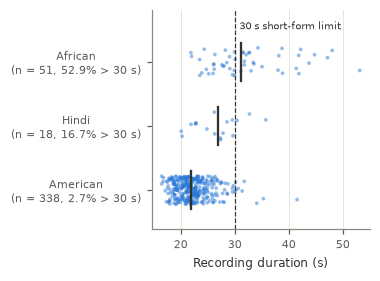

In [20]:
AFRICAN = {"amharic", "hausa", "kiswahili", "tigrigna", "yoruba"}
saa_full["plot_group"] = saa_full["accent"].map(
    lambda a: "African" if a in AFRICAN else ("American" if a == REFERENCE_ACCENT else "Hindi"))

plot_order = saa_full.groupby("plot_group")["duration_s"].median().sort_values().index.tolist()
pct = saa_full.groupby("plot_group")["over_limit"].mean() * 100
n = saa_full["plot_group"].value_counts()

with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    rng = np.random.default_rng(0)
    for i, g in enumerate(plot_order):
        dur = saa_full.loc[saa_full["plot_group"] == g, "duration_s"]
        ax.scatter(dur, i + rng.uniform(-0.22, 0.22, len(dur)), s=6, alpha=0.5,
                   color=BLUE, edgecolor="none")
        ax.plot([dur.median()] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5)
    ax.axvline(SHORT_FORM_LIMIT_S, color=INK, lw=0.8, ls="--")
    ax.set_ylim(-0.6, len(plot_order) - 0.2)
    ax.annotate("30 s short-form limit", (SHORT_FORM_LIMIT_S, len(plot_order) - 0.45),
                xytext=(3, 0), textcoords="offset points", fontsize=6.5, color=INK, va="center")
    ax.set_yticks(range(len(plot_order)),
                  [f"{g}\n(n = {n[g]}, {pct[g]:.1f}% > 30 s)" for g in plot_order])
    for label in ax.get_yticklabels():
        label.set_multialignment("center")
    ax.set_xlabel("Recording duration (s)")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    save_report_figure(fig, "saa_duration_by_group")
    plt.show()

**Analysis of recordings over 30 s:** 

In the full analysis set, 39 of 580 recordings are longer than 30 s, and **all of them are SAA**. AfriSpeech clips are at most 29.9 s (median about 10 s). Within SAA, where everyone reads the same passage, long recordings are heavily concentrated among non-native speakers:

* **American English:** 9 of 338 recordings (2.7%) are over 30 s.
* **Non-American SAA speakers:** 30 of 69 (43.5%) are over 30 s.
* **By accent:** Yoruba 80%, Tigrigna 62%, Amharic 55%, Hausa 44%, Kiswahili 33%, Hindi 17%.

This rules out the alternatives to using long-form everywhere:

* **Short-form for ≤ 30 s and long-form for > 30 s** would decode almost half of the non-native SAA recordings differently from 97% of the American ones, so decode mode would be mixed up with accent.
* **Truncating at 30 s** would cut the end of the passage, adding deletions mainly for non-native speakers and inflating exactly the WER gap being studied.
* **Dropping recordings over 30 s** would remove 43% of the non-native SAA data, and specifically the slowest readers.

Using long-form for every recording avoids all three, and sections 2–6 show that it gives the same WER as short-form where both can be used.

## 8. Repetition (hallucination loops)

Long-form decoding is known to sometimes get stuck repeating a phrase. A hypothesis is flagged if some
`REPEAT_NGRAM`-word phrase appears at least `REPEAT_MIN_COUNT` times **and** more often than in the reference (the SAA
passage itself repeats a few short phrases, which should not count). The ratio of hypothesis length to reference
length is also reported, because a loop makes the transcript much longer than the reference.

In [14]:
def repeated_phrase(hyp, ref, n=REPEAT_NGRAM, min_count=REPEAT_MIN_COUNT):
    """Return the most repeated n-word phrase that occurs >= min_count times and more often than in the reference."""
    h, r = hyp.split(), ref.split()
    hc = Counter(tuple(h[i:i + n]) for i in range(len(h) - n + 1))
    rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
    loops = {g: c for g, c in hc.items() if c >= min_count and c > rc.get(g, 0)}
    if not loops:
        return ""
    g = max(loops, key=loops.get)
    return f"'{' '.join(g)}' x{loops[g]}"

for mode in ["short", "long"]:
    d[f"repeat_{mode}"] = [repeated_phrase(h, r) for h, r in zip(d[f"hypothesis_norm_{mode}"], d["reference_norm_short"])]
    d[f"length_ratio_{mode}"] = d[f"hypothesis_norm_{mode}"].str.split().str.len() / d["n_reference_words_short"]

rep = pd.DataFrame({
    mode: {"recordings with a repeated phrase": int((d[f"repeat_{mode}"] != "").sum()),
           "hypothesis > 1.2x reference length": int((d[f"length_ratio_{mode}"] > 1.2).sum()),
           "max length ratio": d[f"length_ratio_{mode}"].max(),
           "total insertions": int(d[f"insertions_{mode}"].sum())}
    for mode in ["short", "long"]})
print(f"Under-{SHORT_FORM_LIMIT_S:.0f} s subset ({len(d)} recordings):")
display(rep.round(2))
flagged = d[(d["repeat_short"] != "") | (d["repeat_long"] != "")]
if len(flagged):
    display(flagged[["sample_id", "accent", "wer_short", "wer_long", "repeat_short", "repeat_long"]])

Under-30 s subset (370 recordings):


,short,long
recordings with a repeated phrase,0.00,0.00
hypothesis > 1.2x reference length,0.00,0.00
max length ratio,1.17,1.16
total insertions,103.00,108.00


In [15]:
# The same check on the full-study long-form run, where recordings over 30 s really need several windows
if FULL_LONG_RUN_DIR is None:
    print("FULL_LONG_RUN_DIR not set - skipping.")
else:
    fr = load_run(FULL_LONG_RUN_DIR)
    fr = fr.merge(full[["sample_id", "accent", "duration_s", "over_limit"]], on="sample_id", how="left")
    fr["repeat"] = [repeated_phrase(h, r) for h, r in zip(fr["hypothesis_norm"], fr["reference_norm"])]
    fr["length_ratio"] = fr["hypothesis_norm"].str.split().str.len() / fr["n_reference_words"]
    fr["flagged"] = (fr["repeat"] != "") | (fr["length_ratio"] > 2)
    summary = (fr.groupby(["dataset", "over_limit"])
                 .agg(recordings=("flagged", "size"), flagged=("flagged", "sum"),
                      mean_WER=("wer", "mean")))
    summary.index = summary.index.set_names(["dataset", f"over {SHORT_FORM_LIMIT_S:.0f} s"])
    print(f"Full-study long-form run ({len(fr)} recordings): repetition or hypothesis > 2x reference length")
    display(summary.round(3))
    shown = fr[fr["flagged"]].sort_values("wer", ascending=False)
    display(shown[["sample_id", "dataset", "accent", "duration_s", "n_reference_words", "wer", "length_ratio",
                   "repeat"]].round(2))

Full-study long-form run (580 recordings): repetition or hypothesis > 2x reference length


recordings  flagged  mean_WER
dataset    over 30 s                               
afrispeech False             173        4     0.505
saa        False             368        0     0.022
           True               39        0     0.129

,sample_id,dataset,accent,duration_s,n_reference_words,wer,length_ratio,repeat
88,afrispeech_12db0516db3e30de0d08e6eb0cb42370,afrispeech,yoruba,14.62,40,5.55,5.58,'a r t' x72
27,afrispeech_03bcfda67aaa67be96d4e44acadf3615,afrispeech,kiswahili,29.93,12,2.50,3.00,
94,afrispeech_20a455e604ca34b26373f42ea87b791f,afrispeech,yoruba,7.45,7,1.71,2.14,
100,afrispeech_2dd8d783294ab4ef646b0a9bf69ae5a7,afrispeech,yoruba,13.95,19,1.11,1.68,'i i i' x4


**Analysis of repetition:** 

On the under-30 s subset neither mode produced any repeated phrase. The longest hypothesis was 1.17× the reference length (short-form) and 1.16× (long-form), and total insertions were similar (103 vs 108).

In the full-analysis long-form run, **none of the 39 SAA recordings over 30 s** (the ones that genuinely need several windows) showed repetition. Their mean WER is 12.9%, in line with these being mostly non-native speakers.

The four flagged transcripts are all AfriSpeech clips **under 30 s** (7–30 s), so they are not caused by long-form joining windows together. The worst repeated a short fragment ('a r t') 72 times on a 15 s clip (WER 5.55) another is a minor 'i i i' repetition (WER 1.11). AfriSpeech was not run in short-form, so it is not known whether short-form would hallucinate on the same clips.

## 10. Summary

Long-form decoding was used for every recording because the study set contains recordings over 30 s, which short-form cannot transcribe in full. These are almost entirely non-native SAA speakers: 43.5% of their recordings are over 30 s, against 2.7% of the American ones. Mixing decode modes would therefore mix decode mode up with accent, and truncating or dropping the long recordings would bias the non-native results.

On the 370 SAA recordings short enough for both modes, Whisper-base gave the same WER either way: 2.16% (short-form) vs 2.24% (long-form), a difference of +0.09 pp.

* **Most recordings were unaffected:** 86% had exactly the same WER, and 83% exactly the same transcript.
* **The changes were small:** 65% of them were a single error.
* **There was no significant direction:** 32 recordings were worse with long-form and 20 better (sign test p = 0.13).
* **No accent was affected disproportionately:** +0.08 pp for American English vs +0.15 pp for the others.
* **No repetition loops** appeared in either mode on this subset, nor on any of the recordings over 30 s in the full long-form run.

Long-form decoding is therefore a neutral choice that lets every recording be transcribed in the same way.